In [1]:
#%%
import math
import numpy as np
import inspect
import importlib

import scipy.interpolate

import matplotlib
from matplotlib import pyplot as plt
import matplotlib.pyplot as plt

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = 16

import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from plotly.offline import plot
pio.renderers.default = "svg"

import sys
import os
parent_directory = os.path.dirname(os.getcwd())
sys.path.append(parent_directory)
#parent_directory = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
#sys.path.append(parent_directory)
 
import IoT_node_models 
from IoT_node_models import *

path_to_save_svg = "Saved_Data"



Importing IoT Node models
Importing IoT Node description models
Importing IoT Node hardware models
Importing IoT Node profile models
Importing Wireless communication packages
Importing IoT Node deployment strategies
Importing custom components data


In [2]:

#importlib.reload(IoT_node_models)
#from IoT_node_models import *

In [3]:
footprintStructure = FootprintStructure(("GWP", "Money"), units=("$kgCO_2 eq.$", "EUR"))

In [4]:

this_LDO = LDO(name = "Node LDO", category = "Power_supply", v_out = 3.3, i_q = 1e-3, v_in = 3.3, component_list = component_List_3V3)     # XC6206 : 0.228 + Diode and Transistor?

this_Batt= Battery(name = "Node Batt.", category = "Battery", v = 3.3, capacity_mAh = 2800, i = 0, selfdischarge_p_year = 5)


In [5]:
this_hw = Hardware(name= "IoT Node",footprintStructure=footprintStructure, categories=DEFAULT_CATEGORIES)
for comp in component_List_3V3:
    this_hw.add(comp)
this_hw.add(this_LDO)
this_hw.add(this_Batt)

In [6]:

this_profile= LoRa_Profile("Profile", this_hw,  RX_state=radio_state_RX_3V3,TX_state=radio_state_TX_3V3,
                    P_TX= PTX_PABOOST_3V3, I_TX=I_PABoost_3V3 ) 
             

In [7]:

this_task_tx0 = this_profile.create_task_tx(name="TX-0", Ptx = 17,SF=7 ,Coding=1,Header=True,DE = 1,BW = 125e3, Payload = 50, TX_rate=24*1)
this_task_rx0 = this_profile.create_task_rx(name="RX-0", RX_rate=2, RX_duration=0.250 )

this_profile.add_task(task_TPHG_3V3,24*12)
this_profile.add_task(task_TPH_3V3 ,0)

In [8]:
Casing      =this_hw.add(Component(name="Casing", category="Casing",  ))
EoL         =this_hw.add(Component(name="EoL",    category="EoL",     ))
Others      =this_hw.add(Component(name="Others", category="Others",  ))
PCB         =this_hw.add(Component(name="PCB",    category="PCB",     ))
UI          =this_hw.add(Component(name="UI",     category="UI",      ))

In [9]:

this_node = Node_description(name="My_node",hardware=this_hw,profile=this_profile)


In [10]:
def PL_model(d):
    return path_loss_PLd0(d=d, PLd0=94.40,d0=1, n=2.03)

this_task_tx0.set_Path_loss_model(PL_model)

-------------------------------------------------
            Tasks summary                        
-------------------------------------------------
Task name            : TX-0           RX-0           TPHG meas.     TPH meas.      Sleep          
Times/day    [1/d]   : 24             2              288            0              1              
Tot. durat.  [s]     : 55.2468        0.5000         628.7988       0.0000         0.0000         
Tot. en./d   [mJ]    : 21704.5529     18.6120        23482.7893     0.0000         985.5316       
Node en./d   [mJ]    : 46191.4858      
-------------------------------------------------
-----------------------------------------------------------------
                        Module summary                           
-----------------------------------------------------------------
Component    State        Active [s]   Energy [mJ]  Av. Cur.[uA]  
Apollo3                   615.3607     1934.0443    6.7832641     
     -       Active       615.36

d:\Pol\Documents\Research\Git_Iot_node_modeling\IoT_node_models\Node_description\Node_description.py:189: UserWarning: Mismatched number of handles and labels: len(handles) = 3 len(labels) = 8
  ax[1].legend([patches1[i] for i in indexModuleSleep],component_label, bbox_to_anchor=(1,0), bbox_transform=plt.gcf().transFigure, loc="lower right",fontsize = 12)


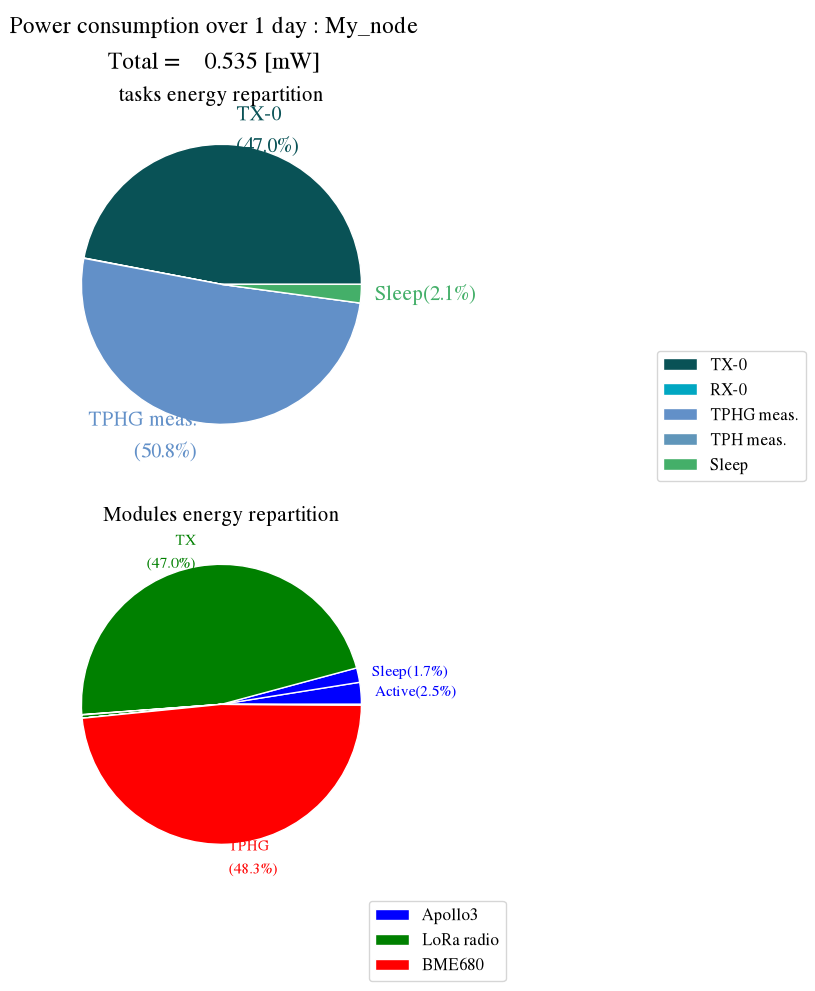

In [11]:
this_task_tx0.set_distance( d= 1500)
this_node.compute()
this_node.print_tasks()
this_node.print_components()
this_node.plot_power()

In [12]:

AA_series = 3
AA_footprint = 0.165
AA_cost      = 0.25 
Batt_footprint = AA_series*AA_footprint
Batt_cost      = AA_series*AA_cost


Connectivity = radio_component_3V3
Processing   = apollo_component_3V3
Sensing      = bme_component_3V3
Power_supply = this_LDO

In [13]:
Casing                  .set_factors(footprintStructure.vector(GWP=(0.3932,   0.709,   1.3259), Money=10))
Connectivity            .set_factors(footprintStructure.vector(GWP=(0.2262,   0.517,   0.5817), Money=5.3))   # SX1276 : 5.3
EoL                     .set_factors(footprintStructure.vector(GWP=(0.0388,   0.0812,  0.1201), Money=0))
Others                  .set_factors(footprintStructure.vector(GWP=(0.0546,   0.0938,  0.1394), Money=1.42))
PCB                     .set_factors(footprintStructure.vector(GWP=(0.9403,   1.17,    1.5696), Money=1.17))
Power_supply            .set_factors(footprintStructure.vector(GWP=(0.0446,   0.132,   0.1751), Money=0.228))
Processing              .set_factors(footprintStructure.vector(GWP=(0.366,    0.366,   0.4537), Money=3.65))   # Apollo3: 3.65this_Batt= Battery(name = "Node Batt.", category = "Battery", v = 3.3, capacity_mAh = 2800, i = 0, selfdischarge_p_year = 5,
Sensing                 .set_factors(footprintStructure.vector(GWP=(0.0539,   0.0539,  0.5561), Money=6.94)) 
UI                      .set_factors(footprintStructure.vector(GWP=(0.0017,   0.0306, 0.1155), Money=0.54))
this_Batt               .set_factors(footprintStructure.vector(GWP=(Batt_footprint  ,Batt_footprint,Batt_footprint), Money=Batt_cost))


Category      GWP [$kgCO_2 eq.$]       Money [EUR]
------------  -----------------------  -----------
Casing        [0.393, 0.709, 1.33]     10         
Connectivity  [0.226, 0.517, 0.582]    5.3        
EoL           [0.0388, 0.0812, 0.12]   0          
Memory        0                        0          
Others        [0.0546, 0.0938, 0.139]  1.42       
PCB           [0.94, 1.17, 1.57]       1.17       
Power_supply  [0.0446, 0.132, 0.175]   0.228      
Processing    [0.366, 0.366, 0.454]    3.65       
Sensing       [0.0539, 0.0539, 0.556]  6.94       
UI            [0.0017, 0.0306, 0.116]  0.54       
Battery       0.495                    0.75       
------------  -----------------------  -----------
Total         [2.61, 3.65, 5.53]       30         


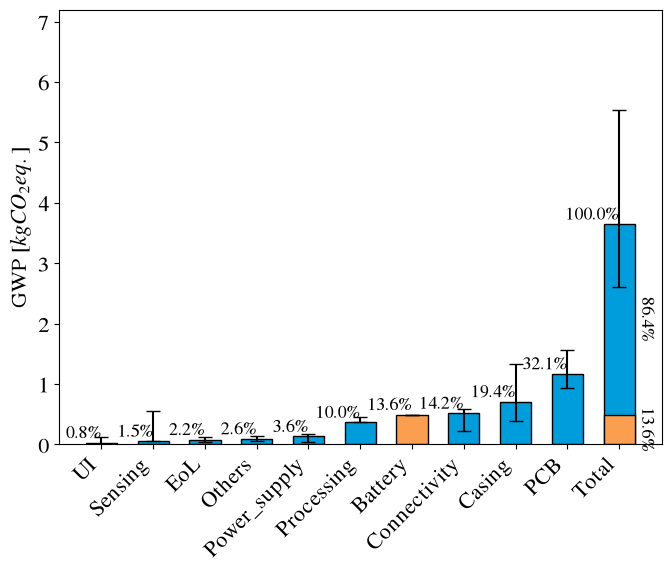

In [14]:

this_hw.compute_footprint()
this_hw.report_footprint()
this_hw.plot_footprint(label="GWP")

In [15]:

#importlib.reload(IoT_node_models)
#from IoT_node_models import *

In [17]:
Nyears=30

placementNnodes   = 100
decomNnodes       = 100
replacementNnodes = 10

#placementTransport      = Transport(n_node=placementNnodes  , km_fixed=5, km_p_node=80, footprint_p_km=0.350, label="GWP")
#decomTransport          = Transport(n_node=decomNnodes      , km_fixed=5, km_p_node=80, footprint_p_km=0.350, label="GWP")
#replacementTransport    = Transport(n_node=replacementNnodes, km_fixed=5, km_p_node=80, footprint_p_km=0.350, label="GWP")

placementTransport      = Dum_Transport(n_node=placementNnodes  , km_fixed=40, km_p_node=5, footprint_p_km=0.350, label="GWP")
decomTransport          = Dum_Transport(n_node=decomNnodes      , km_fixed=40, km_p_node=5, footprint_p_km=0.350, label="GWP")
replacementTransport    = Dum_Transport(n_node=replacementNnodes, km_fixed=40, km_p_node=5, footprint_p_km=0.350, label="GWP")

deploymentStart = DeploymentStrategy_wTransport( Nyears=Nyears, replacementCategories=None,#("Battery",),
                  transport_placement     =placementTransport, 
                  transport_replacement   =replacementTransport, 
                  transport_decom         =decomTransport,
                  smooth_replacement_footprint = True)

this_node.set_deployment_strategy(deploymentStart)
this_node.compute()

d:\Pol\Documents\Research\Git_Iot_node_modeling\IoT_node_models\Node_description\Node_description.py:328: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


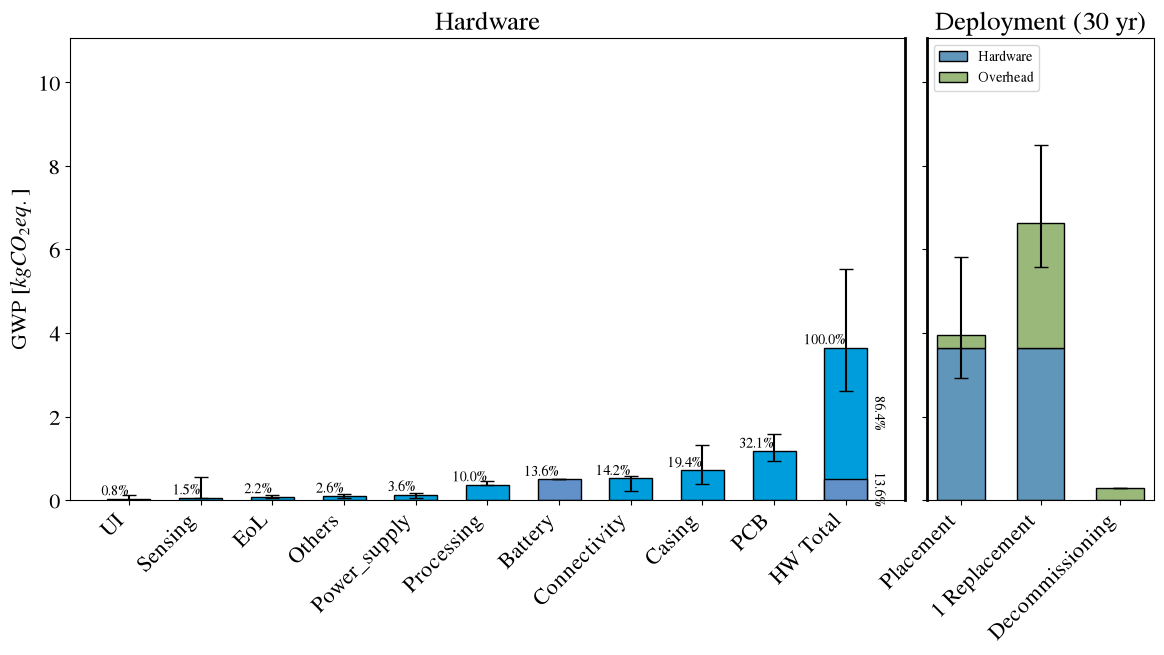

In [19]:
this_node.plot_footprint(label="GWP",cumulated_replacement=False)

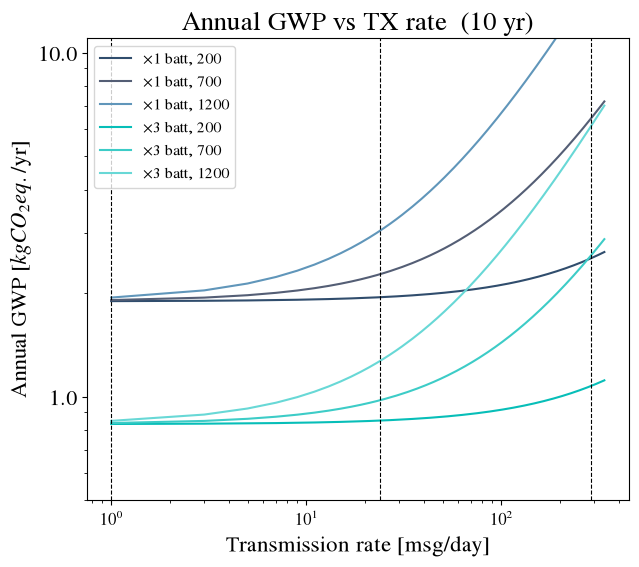

In [19]:
this_node.deployment_strategy.Nyears = 10

fig, ax = sweep_fdata(this_node, this_task_tx0,
    label="GWP", fmin=1, fmax=24*12+50, f_step=2,
    nAA=[1, 3],
    param_values=[200, 700, 1200], paramType="dnode", ylim = (0.5,11))

this_node.deployment_strategy.Nyears = Nyears

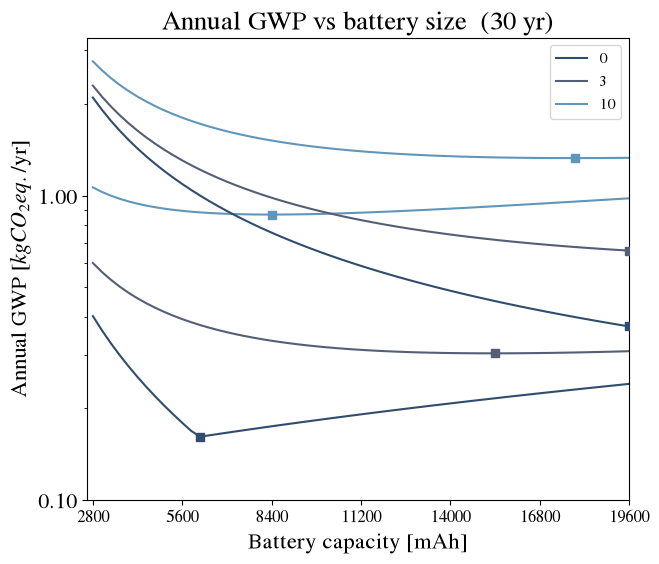

In [23]:

this_node.profile.change_task_rate(this_task_tx0,24)
this_task_tx0.set_distance(d= 700)


this_node.profile.change_task_rate(task_TPHG_3V3,0)
this_node.profile.change_task_rate(task_TPH_3V3 ,24*12)

# sweep battery size — three self-discharge values
fig, ax = sweep_ebatt(this_node,
    label="GWP", nAAmin=1, nAAmax=7, nAA_step=0.1,
    param_values=[0, 3, 10], paramType="rsd", ylim =(0.1,  3.3), xlim = (2600,19600))


this_node.profile.change_task_rate(task_TPHG_3V3,24*12)
this_node.profile.change_task_rate(task_TPH_3V3 ,0)

# sweep battery size — three self-discharge values
fig, ax = sweep_ebatt(this_node,
    label="GWP", nAAmin=1, nAAmax=7, nAA_step=0.1,
    param_values=[0, 3, 10], paramType="rsd", figAppend = [fig, ax] )

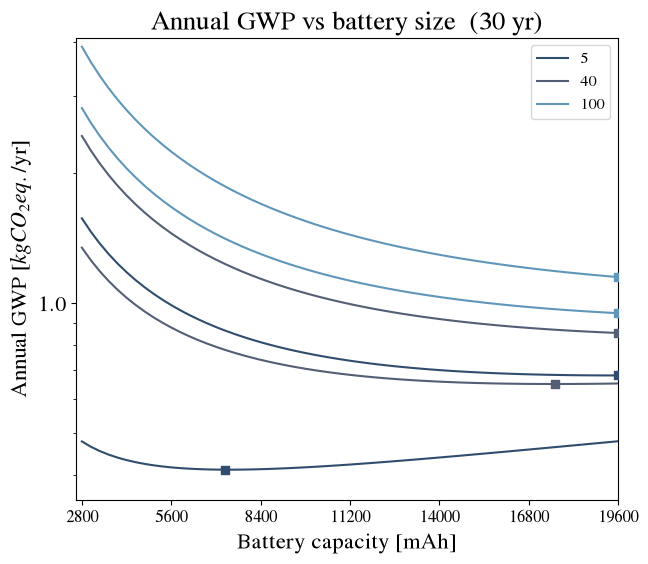

In [27]:

fig, ax = sweep_ebatt(this_node,
    label="GWP", nAAmin=1, nAAmax=7, nAA_step=0.1,
    transport_refs=[placementTransport, decomTransport, replacementTransport],
    replacementCategories=None,
    param_values=[5,40,100], paramType="dtrans", ylim =(0.35, 4.1) , xlim = (2600,19600))

fig, ax = sweep_ebatt(this_node,
    label="GWP", nAAmin=1, nAAmax=7, nAA_step=0.1,
    transport_refs=[placementTransport, decomTransport, replacementTransport],
    replacementCategories=("Battery",),
    param_values=[5,40,100], paramType="dtrans",  figAppend=[fig,ax] )

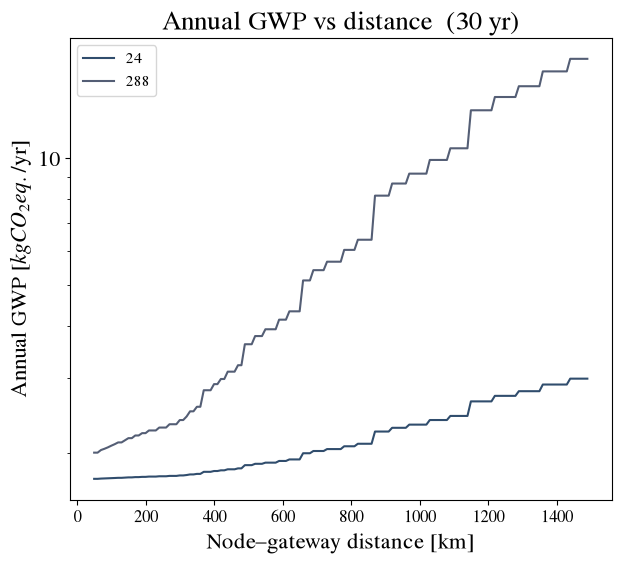

In [341]:

# sweep distance — two TX rates
fig, ax = sweep_dnode(this_node, this_task_tx0,
    label="GWP", dmin=50, dmax=1500, d_step=10,
    param_values=[24, 24*12], paramType="fdata")